# USDJPY forward-return prediction (LightGBM)

Predict USDJPY from Yahoo Finance 1h bars (`yfinance`, `USDJPY=X`) with a leak-free walk-forward
evaluation. The project mirrors the experiment pipeline of `delivery-time-prediction`: versioned experiment
modules → one `execute()` call → leaderboard / diagnostics / experiments → refit → artefacts →
pre/post-analysis report.

There are two experiment arms:

| arm | objective | selection |
|---|---|---|
| `v002_fwd_logret_1d` (default) | **1-day forward log return**, `y_t = log(close[t+25] / close[t+1])`. This is the same target as ml-pipe's `v001_logreturn_exp_v19_legacy_test` (`FWDLogReturn(48, 1)` on 30-min bars), regression | Spearman |
| `v001_lgbm_walkforward` | next-hour direction, `close[t+1] > close[t]`, classification | ROC AUC |

## Run it

Everything runs in Docker (`make help` lists the targets):

```bash
make build          # image with numpy/pandas/sklearn/lightgbm/yfinance/jupyter
make fetch          # download ~2.8 years of 1h bars -> dataset/usdjpy_1h.csv (the only network step)
make test           # unit tests on synthetic random-walk bars (no network)
make train          # v002 end-to-end -> outputs/ (leaderboard, holdout score, predictions.csv, model.joblib)
make train EXP=v001_lgbm_walkforward   # the next-hour direction arm
make predict        # forecast from the latest cached bar with the saved model
make experiments    # experiment ladder (TASK=return|direction) -> outputs/experiments.json
make run-report     # re-execute this notebook; `make report` exports REPORT.html; `make readme` refreshes README.md
```

Options: `EXP=<module>`, `MODELS=persistence,ridge,lgbm_reg` (empty = the arm's set), `CV=5`, `SEED=0`,
`COST=0.5` (bp per unit position change).

## Layout

| path | role |
|---|---|
| `usdjpy/data.py` | yfinance download + CSV cache, targets (`make_target`, `make_forward_return_target`), purged chronological holdout |
| `usdjpy/features.py` | `BarCleaner` (optional FX-week grid), `BarFeatureEngineer` (v001), `MultiWindowFeatureEngineer` (ml-pipe feature set), encoders |
| `usdjpy/models.py` | direction candidates (`majority`, `momentum`, `logreg`, `lgbm`), return regressors (`persistence`, `mean`, `best_feature`, `random`, `ridge`, `lgbm_reg`) |
| `usdjpy/evaluation.py` | `DirectionEvaluator` / `ReturnEvaluator` (walk-forward `TimeSeriesSplit` + gap), metrics, slices, displays |
| `usdjpy/pipeline/classification.py` | `execute()`: the 10 phases, task-aware |
| `usdjpy/analysis/` | builders, display helpers, pre/post-analysis reporters |
| `usdjpy/exp/` | the experiment arms (copy the latest to `v00N_*.py` to change one thing) |
| `usdjpy/train.py`, `usdjpy/experiments.py` | CLI and experiment ladder |

## Method (v002, aligned with ml-pipe)

| | ml-pipe `v001_logreturn_exp_v19_legacy_test` | here (`v002_fwd_logret_1d`) |
|---|---|---|
| bars | 30 min, FX week Sun 17:00 → Fri 16:59 New York | 1h (Yahoo keeps 30-min history for 60 days only), same FX-week grid, missing hours forward-filled |
| target | `FWDLogReturn(lookahead_window=48, lookahead_offset=1)` | `log(close[t+25] / close[t+1])`: the same 1-day window after a 1-bar buffer |
| features | 18 `tsf` types × windows 1.5h…63d × shifts {0, 1 day}, over a selected cross-asset universe | the same 18 types and clock windows (2, 6, 12, 24, 120, 504, 1512 bars) × shifts {0, 23}, **USDJPY only**: 234 features |
| model | feature selection → sparse mixture-of-experts net, robust-scaled/clipped target | `LGBMRegressor` on a robust-scaled, ±5-clipped target |
| baselines | persistence, mean, best_feature, random_sample | persistence, mean, best_feature, random, + ridge |
| validation | rolling 1.5y train, 16-day skip, 6-month roll | 5-fold walk-forward, 16-day gap (274 bars); rolling 1.5y window as an experiment; last 15% held out, purged by 25 bars |
| metrics | Spearman, Pearson, MSE, R², MCC, … | Spearman (selection), Pearson, R², MSE, MCC, AUC/hit rate of the sign, daily sign trade on non-overlapping labels |

**Leakage guards.**
- Every feature is invariant to truncating or shocking the future (tested).
- A random walk scores Spearman ≈ 0 through the evaluator.
- No development label overlaps the holdout or a test fold.

The cells below re-run v002 and render the full report.

In [1]:
%matplotlib inline
import json, warnings
from pathlib import Path

import pandas as pd
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

from usdjpy.analysis import display_dataframe, display_info_box
from usdjpy.exp import v002_fwd_logret_1d as exp

[v002_fwd_logret_1d] Step2: 17,472 bars -> 13,500 dev rows + 2,387 holdout rows (from 2026-06-10 11:00:00+00:00)


,count
gap length,
48h,3
49h,120
50h,2


,Mon,Tue,Wed,Thu,Fri,Sun
bars,3024,3010,3000,3000,2669,332


,mean_bp,std_bp,skew,kurtosis,p01_bp,p99_bp,up_share,n
forward log return,0.8147,63.0317,-0.7685,3.6217,-197.0907,155.474,0.5625,13500


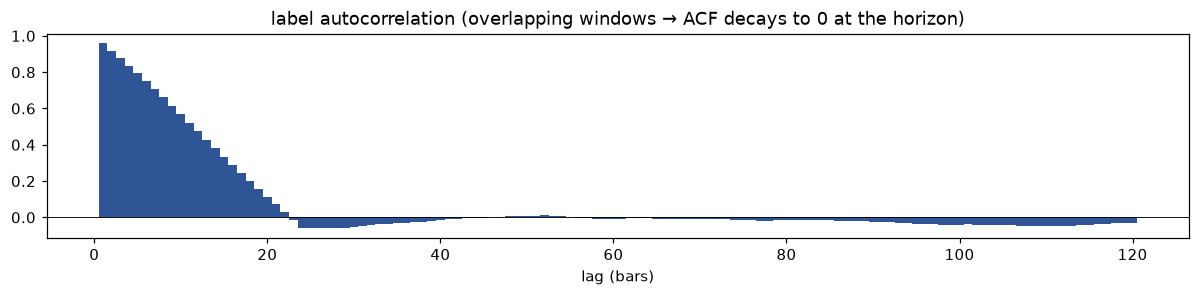

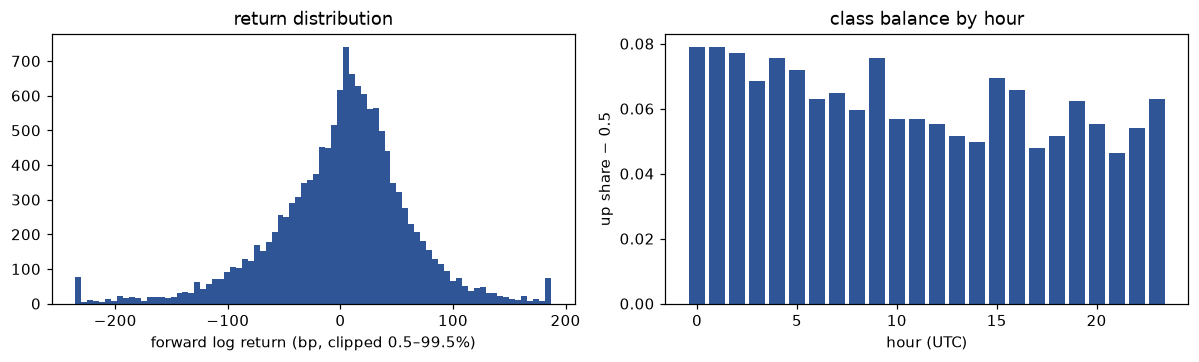

Up share 0.5625; by hour it ranges 0.546–0.579 (±1σ sampling noise per hour ≈ 0.021).

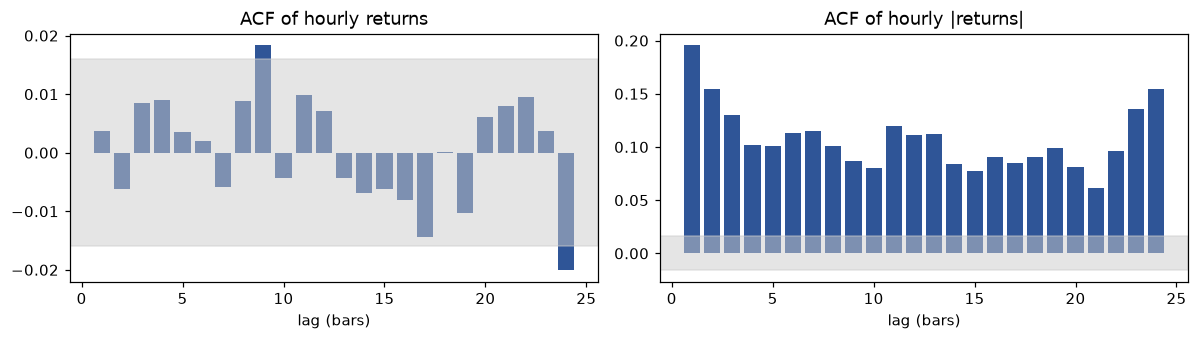

Return ACF outside the ±0.0160 band at lags [9, 24]; |return| ACF at lag 1 = 0.196 (volatility clusters, direction mostly does not).

,mean,std,min,max,missing,spearman_next_ret
skew_w120_s0,-0.0386,0.6246,-2.8428,3.7428,0.0,-0.0707
rsi_w120_s0,0.0233,0.1325,-0.3537,0.5898,0.0,-0.0703
we_volatility_w120_s0,0.7499,0.4425,0.1019,4.0683,0.0,-0.0656
rsi_w120_s23,0.0234,0.1326,-0.3537,0.5898,0.0,-0.0654
pct_change_w120_s0,0.0005,0.0133,-0.0756,0.0475,0.0,-0.0652
diff_w120_s0,0.0708,2.0147,-11.6360,6.7260,0.0,-0.0650
we_volatility_w24_s0,0.3250,0.2415,0.0004,2.1830,0.0,-0.0618
change_skew_w120_s0,-0.1862,1.7688,-8.8174,6.8474,0.0,-0.0601
zscore_w120_s0,0.2024,1.3817,-3.0000,3.0000,0.0,-0.0601
volatility_w24_s0,0.3194,0.2287,0.0006,1.9578,0.0,-0.0584


Largest |ρ| = 0.0707 (n = 13,500; ±2σ noise ≈ 0.0172). Single features carry very little linear signal.

[v002_fwd_logret_1d] Step4: 6 candidates: ['persistence', 'mean', 'best_feature', 'random', 'ridge', 'lgbm_reg']


[v002_fwd_logret_1d] Step5: walk-forward CV with TimeSeriesSplit(gap=274, max_train_size=None, n_splits=5, test_size=None)


...

[v002_fwd_logret_1d] Step8: holdout spearman -0.0266, hit 0.5019, strategy +4.374 bp/day


[v002_fwd_logret_1d] Step9: artefacts under /Users/alhabib/Desktop/glitcj-repos/alpha-discovery/usdjpy-direction/outputs (31.3s)


,spearman,spearman_fold_std,pearson,r2,mse,mcc,auc,hit_rate,strategy_bps,sharpe,n,fit_time_s
model,,,,,,,,,,,,
random,-0.0025,0.0181,0.0073,-1.4737,0.0001,0.0014,0.5032,0.5059,-2.1939,-0.5768,11250.0000,0.0023
lgbm_reg,-0.0128,0.0414,-0.0261,-0.7316,0.0001,-0.0143,0.4970,0.4804,-0.4565,-0.1200,11250.0000,1.2194
ridge,-0.0369,0.0393,-0.0330,-36.2747,0.0013,-0.0251,0.4822,0.4820,-1.4545,-0.3824,11250.0000,0.0825
persistence,-0.0595,0.0655,-0.0740,-1.1465,0.0001,-0.0245,0.4707,0.4936,-2.0883,-0.5503,11250.0000,0.0031
best_feature,-0.0631,0.0624,-0.0620,-0.0845,0.0000,0.0511,0.4986,0.5033,-2.5381,-0.6677,11250.0000,0.1617
mean,-0.0675,0.0387,-0.0658,-0.0668,0.0000,-0.0503,0.4734,0.4824,-5.7083,-1.5063,11250.0000,0.0023


,test_start,test_end,n_train,n_test,spearman,pearson,r2,mse,mcc,auc,hit_rate,pred_up_share,strategy_bps,sharpe
fold,,,,,,,,,,,,,,
0,2024-08-21 16:00:00+00:00,2024-12-31 10:00:00+00:00,1976,2250,-0.0002,0.0003,-1.3315,0.0001,-0.0064,0.5031,0.5089,0.5809,-4.9824,-1.1236
1,2024-12-31 11:00:00+00:00,2025-05-12 03:00:00+00:00,4226,2250,-0.0097,-0.0005,-1.1491,0.0001,-0.0077,0.4926,0.4924,0.5729,9.1261,2.0958
2,2025-05-12 04:00:00+00:00,2025-09-18 21:00:00+00:00,6476,2250,0.0346,0.0455,-1.4658,0.0001,0.0157,0.5197,0.5080,0.5316,6.8329,1.9901
3,2025-09-18 22:00:00+00:00,2026-01-28 16:00:00+00:00,8726,2250,-0.0162,0.0022,-1.8240,0.0001,-0.0019,0.4977,0.5013,0.5258,-2.6790,-0.8206
4,2026-01-28 17:00:00+00:00,2026-06-09 09:00:00+00:00,10976,2250,-0.0089,0.0102,-2.2411,0.0001,0.0174,0.5127,0.5187,0.5333,-4.9331,-1.6665


,spearman,pearson,r2,mse,mcc,auc,hit_rate,strategy_bps,sharpe,fit_time_s
model,,,,,,,,,,
lgbm_reg,0.0974,0.0800,-0.2106,0.0000,-0.0257,0.5075,0.4592,-1.1331,-0.3646,1.4636


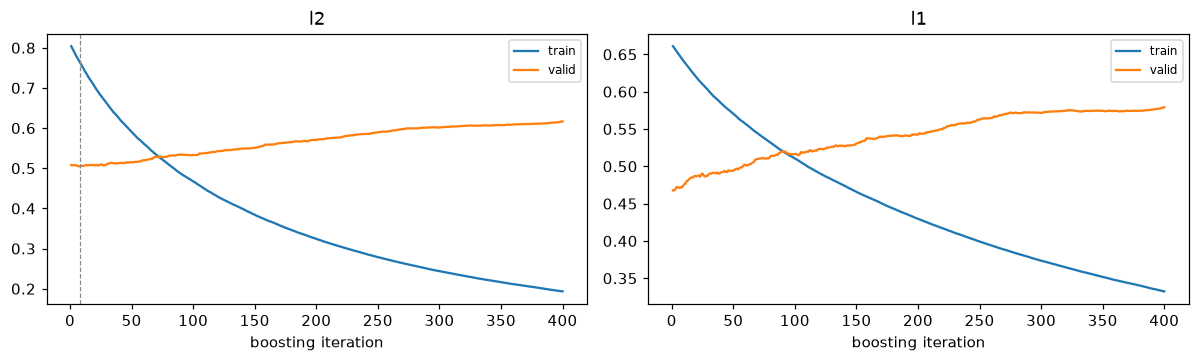

`lgbm_reg`: best validation l2 0.5044 at iteration 8 of 400. A widening train/valid gap means the extra trees fit noise.

,spearman,spearman_fold_std,pearson,r2,mse,mcc,auc,hit_rate,strategy_bps,sharpe,n,fit_time_s
model,,,,,,,,,,,,
random,-0.0025,0.0181,0.0073,-1.4737,0.0001,0.0014,0.5032,0.5059,-2.1939,-0.5768,11250.0000,0.0023
lgbm_reg (rolling ~1.5y window),-0.0217,0.0381,-0.0296,-0.7562,0.0001,-0.0363,0.4813,0.4686,-1.0293,-0.2706,11250.0000,1.2140
lgbm_reg (+ calendar features),-0.0260,0.0342,-0.0347,-0.7750,0.0001,-0.0288,0.4880,0.4767,-0.3543,-0.0931,11250.0000,1.5908
lgbm_reg (shift 0 only),-0.0330,0.0459,-0.0423,-0.8319,0.0001,-0.0009,0.4905,0.4876,-1.6979,-0.4465,11250.0000,1.0962


,n,share,up_share,mean_y_bp,spearman,hit_rate
slice,,,,,,
tokyo,3283.0000,0.2918,0.5705,2.1028,-0.0005,0.5102
tokyo+london,938.0000,0.0834,0.5554,2.0759,-0.0561,0.4925
london,1405.0000,0.1249,0.5552,2.0094,-0.0203,0.4954
london+ny,1872.0000,0.1664,0.5513,1.9719,0.0630,0.5203
ny,2345.0000,0.2084,0.5510,2.1607,-0.0175,0.4968
off-hours,1407.0000,0.1251,0.5480,2.0596,-0.0191,0.5110


,n,share,up_share,mean_y_bp,spearman,hit_rate
slice,,,,,,
00-03,1876.0000,0.1668,0.5730,2.0822,0.0135,0.5187
04-07,1876.0000,0.1668,0.5650,2.1158,-0.0343,0.4947
08-11,1874.0000,0.1666,0.5544,2.0268,-0.0241,0.4973
12-15,1872.0000,0.1664,0.5513,1.9719,0.0630,0.5203
16-19,1876.0000,0.1668,0.5512,2.1688,-0.0195,0.4936
20-23,1876.0000,0.1668,0.5485,2.0767,-0.0163,0.5107


,n,share,up_share,mean_y_bp,spearman,hit_rate
slice,,,,,,
Mon,2256.0000,0.2005,0.5448,2.2505,0.0296,0.5230
Tue,2242.0000,0.1993,0.5834,6.0683,-0.0384,0.4902
Wed,2240.0000,0.1991,0.5594,2.2412,0.0009,0.5116
Thu,2256.0000,0.2005,0.5652,-1.1621,-0.0234,0.5022
Fri,2010.0000,0.1787,0.5343,0.5010,0.0203,0.4980
Sun,246.0000,0.0219,0.5285,5.0485,-0.0226,0.5366


,n,share,up_share,mean_y_bp,spearman,hit_rate
slice,,,,,,
low vol,3750.0000,0.3333,0.5715,3.4121,-0.0097,0.5075
mid vol,3750.0000,0.3333,0.5864,5.4641,0.0178,0.5187
high vol,3750.0000,0.3333,0.5139,-2.6549,-0.0152,0.4915


,n,share,up_share,mean_y_bp,spearman,hit_rate
slice,,,,,,
q1 (smallest |pred|),2820.0000,0.2507,0.5535,2.6550,-0.0315,0.5043
q2,2807.0000,0.2495,0.5582,2.0492,0.0122,0.5126
q3,2812.0000,0.2500,0.5626,1.7645,-0.0103,0.5082
q4 (largest |pred|),2811.0000,0.2499,0.5546,1.8246,0.0154,0.4984


Read the confidence table first: a usable model's hit rate should rise with the size of the predicted return. Here the top bucket hits 0.498 on n = 2811.

,spearman,spearman_fold_std,pearson,r2,mse,mcc,auc,hit_rate,strategy_bps,sharpe,n,fit_time_s
model,,,,,,,,,,,,
random (CV),-0.0025,0.0181,0.0073,-1.4737,0.0001,0.0014,0.5032,0.5059,-2.1939,-0.5768,11250.0000,0.0023
random (holdout),-0.0266,nan,-0.0152,-1.6467,0.0001,-0.0099,0.4905,0.5019,4.3738,1.3286,2387.0000,nan


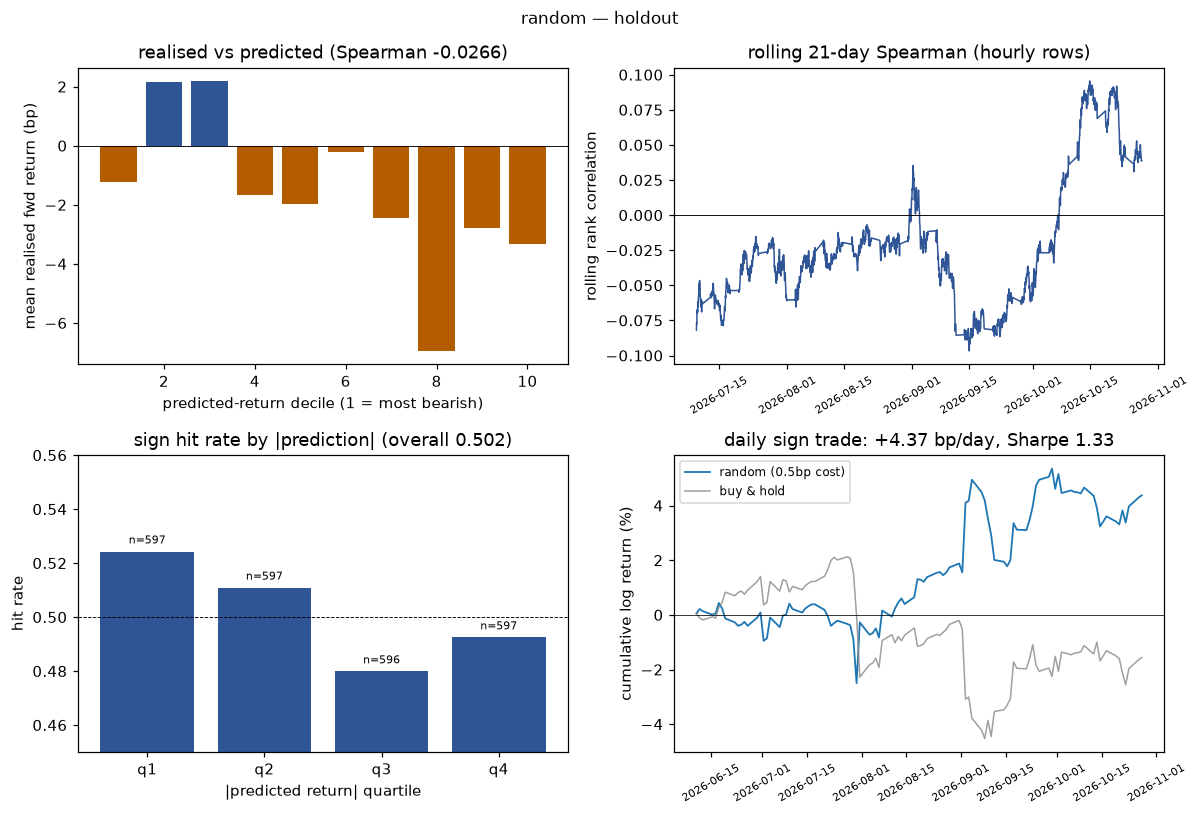

In [2]:
result = exp.run(display_preanalysis=True, display_postanalysis=True)

## Experiment ladder

`make experiments` evaluates a wider set of v002 variants on the same development rows and walk-forward
folds (holdout excluded). The table is read from `outputs/experiments.json`.

In [3]:
path = Path("outputs/experiments.json")
if path.exists():
    ladder = json.loads(path.read_text())
    board = pd.DataFrame(ladder["results"]).set_index("model")
    display_dataframe(board, f"{ladder.get('task', 'direction')} task — {ladder['cv']}-fold walk-forward, "
                             f"gap {ladder['gap']}, dev rows {ladder['n_dev']:,} "
                             f"({ladder['dev_start'][:10]} → {ladder['dev_end'][:10]})")
else:
    display_info_box("outputs/experiments.json not found — run `make experiments`.", kind="warning")

,spearman,spearman_fold_std,pearson,r2,mcc,hit_rate,strategy_bps,sharpe,fit_time_s
model,,,,,,,,,
"lgbm_reg: library defaults (100 trees, 31 leaves)",0.0126,0.0506,0.0116,-0.7383,0.0456,0.4967,3.1043,0.8175,0.7805
random (sampled targets),-0.0025,0.0181,0.0073,-1.4737,0.0014,0.5059,-2.1939,-0.5768,0.0021
lgbm_reg: windows <= 1 day,-0.0075,0.0276,0.0020,-0.1543,-0.0035,0.5012,-1.5878,-0.4176,1.1063
lgbm_reg: huber objective,-0.0125,0.0342,-0.0166,-0.4424,-0.0299,0.4805,0.5019,0.1320,1.2103
lgbm_reg: tuned (v002),-0.0128,0.0414,-0.0261,-0.7316,-0.0143,0.4804,-0.4565,-0.1200,1.2100
lgbm_reg: windows >= 5 days,-0.0134,0.0415,-0.0334,-0.7834,-0.0110,0.4836,0.9323,0.2452,1.0827
lgbm_reg: pct_change only,-0.0203,0.0598,-0.0292,-0.4717,0.0255,0.5010,-1.0374,-0.2728,0.9718
lgbm_reg: + calendar,-0.0260,0.0342,-0.0347,-0.7750,-0.0288,0.4767,-0.3543,-0.0931,1.5325
ridge: alpha=1000,-0.0299,0.0669,-0.0333,-3.4777,-0.0008,0.4943,-0.5825,-0.1531,0.0808


## Findings (data 2024-01-15 → 2026-10-28)

### v002: 1-day forward log return (ml-pipe objective)

* **No model predicts the 1-day return.** Out-of-fold Spearman: `lgbm_reg` −0.013, `ridge` −0.037,
  `persistence` −0.060, `best_feature` −0.063, `mean` −0.068, `random` −0.003. The labels overlap by
  24 bars, so 11k hourly rows hold only ~470 independent days, and Spearman's noise is about ±0.05.
  Every model is inside that band, and the leaderboard winner is the `random` baseline.
* **Variants don't change that.** Across 14 variants in the ladder, the range is −0.068 to +0.013:
  library-default LightGBM, a huber loss, short-only or long-only windows, shift-0 only, pct_change only,
  adding calendar features, a rolling 1.5-year window, and two ridge strengths. The best single feature
  in-sample (5-day skew/RSI/momentum, |ρ| ≈ 0.07) does not carry over out of sample.
* **The holdout agrees.** On Jun–Oct 2026, Spearman is ≈ −0.03 and the sign hit rate ≈ 0.50.
* **Comparison with ml-pipe.** The ml-pipe arm gets its edge, if any, from cross-asset inputs selected
  over a 40-asset universe and from 4 more years of history. Neither exists here: we have USDJPY only and
  ~2.8 years on Yahoo. A null result on USDJPY-only features is the expected baseline for that comparison.
* **Data sanity.** Labels match the raw closes. No feature is NaN or constant after warm-up. About 2%
  of FX-week hours are forward-filled gaps.

### v001: next-hour direction (kept for reference)

* LightGBM CV AUC 0.519 (holdout 0.558). Most of the signal is time-of-day; it is too small to survive
  0.5 bp costs.

## Next arms

* `v003`: add cross-asset inputs, the main difference from ml-pipe. Pull 1h bars for EURUSD, GBPJPY,
  AUDJPY, DXY, ^N225, ^GSPC and ^TNX, align them to the USDJPY grid, and build the same multi-window
  features on each.
* `v004`: ml-pipe-style feature selection (stability-ranked Spearman / Pearson, top-N grid) before
  LightGBM, once there are thousands of cross-asset features.
* For more history or 30-min bars, switch to a documented data source (see
  `planning-1hour-price-direction-classification.md`) or the Tiingo/Sharadar parquet files ml-pipe uses.